# Deep-dive on `NNInterpolator` tuning

In this notebook we perform a detailed analysis of the different features and hyperparameters that can be tuned when the neural network model is created and trained to better understand how it works. It is recommended to read [getting_started.ipynb](./getting_started.ipynb) before reading this notebook.

First of all, we are going to import the main library classes `Loader` and `NNInterpolator` and load a simple 1D dataset ([example1a.csv](../examples/example1a.csv)) as a first example.

In [4]:
from nninterpolator import Loader, NNInterpolator

dls = Loader(trn_perc=0.8, batch_sz=50).from_csv('../examples/example1a.csv', x_cols=0, y_cols=1)

We know that [example1a.csv](../examples/example1a.csv) contains 300 samples in total, so a training set of $300 \cdot 0.8 = 240$ samples divided in $240 / 50 \approx 5$ minibatches of 50 samples each seems just fine. On the one hand, a lower training sample percentage (`trn_perc`) would lead to a lower amount of data for the model to train. On the other hand, a smaller minibatch size (`batch_sz`) would lead to greater iterations per epoch (i.e. faster convergence but longer iterations) and a bigger size would result in less iterations per epoch (i.e. slower convergence but shorter iterations).

Now that we loaded the dataset and we understand its format and dimensions, we can experiment with the different features of our neural network.

## Network depth and width

When we initialize a `NNInterpolator` object, we need to define the total amount of layers that the neural network is going to have (`nlay` --> *network depth*) and also the amount of neurons in each one (`lay_sz` --> *network width*).

### `nlay`

First we can test how the results vary as we change the number of layers that form our NN keeping everything else constant (and making sure that `nepochs` is big enough for an acceptable fit):

nlay = 1


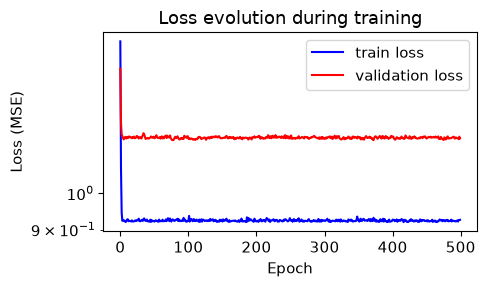

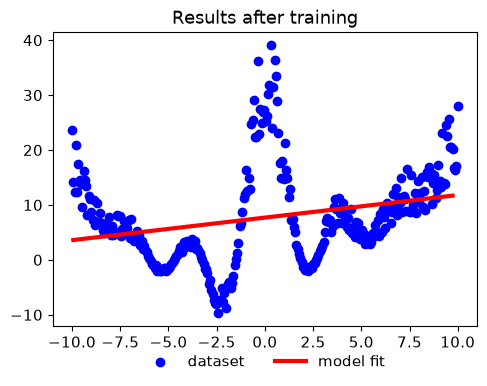

nlay = 2


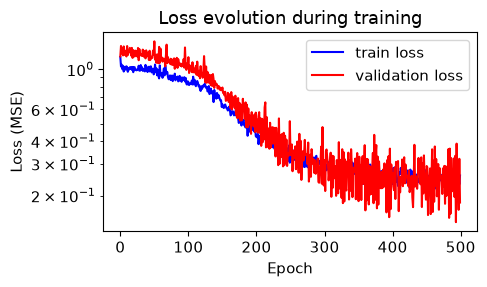

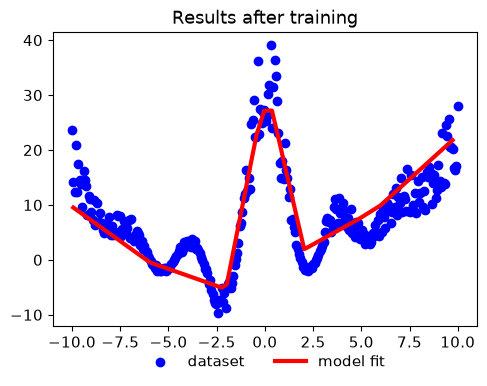

nlay = 3


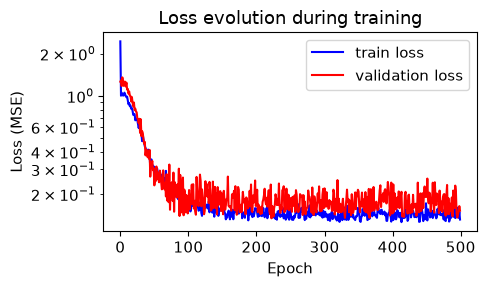

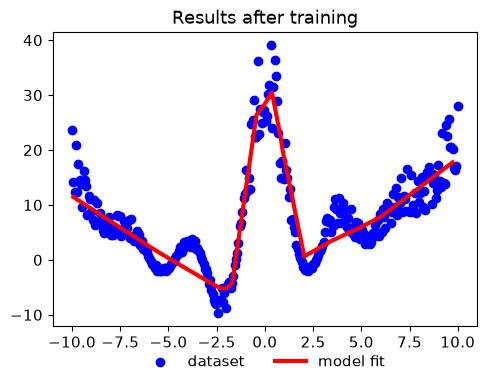

nlay = 4


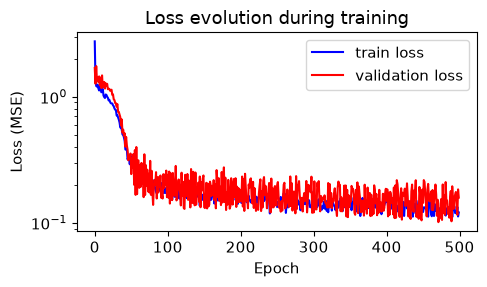

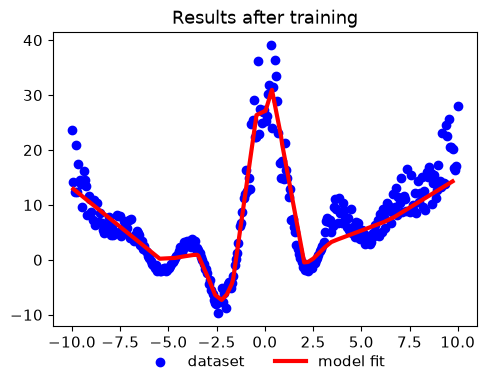

nlay = 10


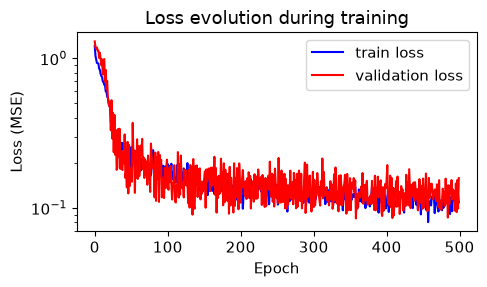

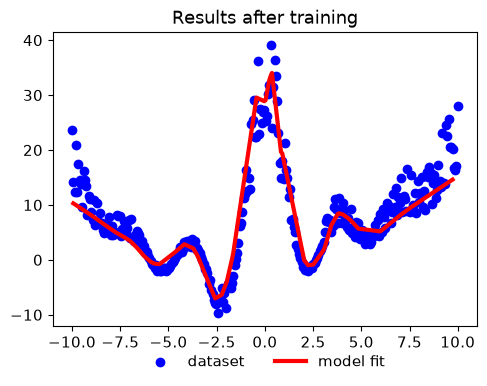

In [9]:
n = [1, 2, 3, 4, 10]
for nlay in n:
    print(f'nlay = {nlay}')
    history = NNInterpolator(nlay=nlay, lay_sz=64).fit(dls, lr=0.1, nepochs=500, plot=True)

As we can see, a NN with a single layer (**n=1**) will be unable to fit any non-linear feature, as it can only give a linear output (i.e. a straight line with the overall slope). However, for **n>1** the model starts to pick up more and more features from the dataset. This happens because the presence of ReLU activation functions between the different layers (which are non-linear) lets to a more and more complex output.

This means that, in theory, the more layers our network has, the more complex features it will be able to fit correctly. But the more the layers of our network the more it will take to train, so we need to pick a balanced option. In this case, given that the dataset is not that complex, a network of **n=4** will be more than enough.

### `lay_sz`

Now, fixing `nlay=4`, we can vary the width of the layers:

lay_sz = 1


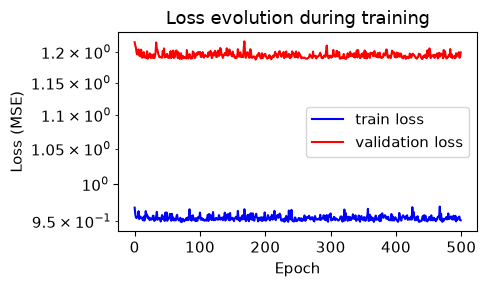

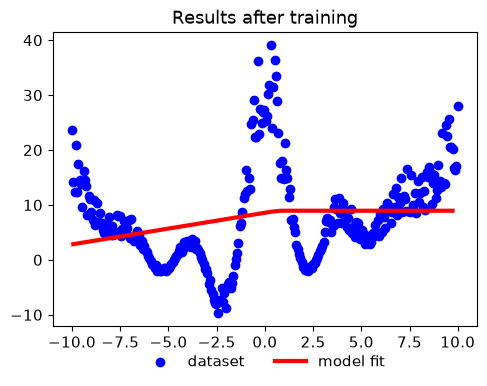

lay_sz = 32


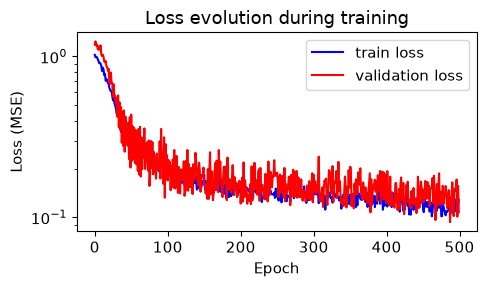

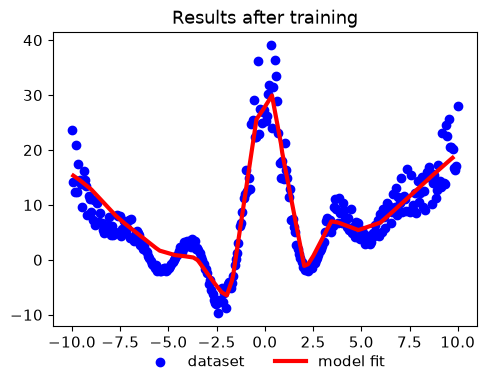

lay_sz = 64


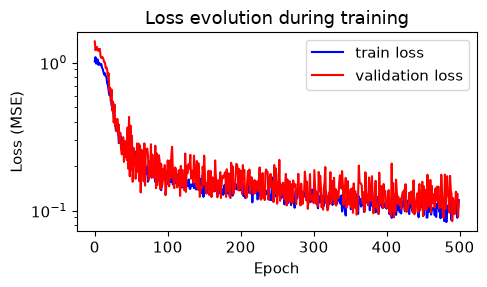

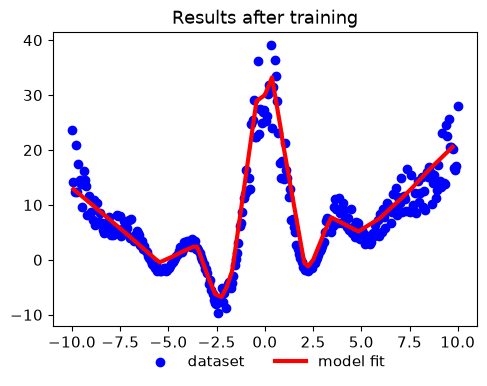

lay_sz = 128


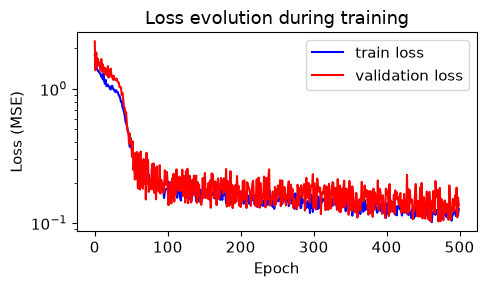

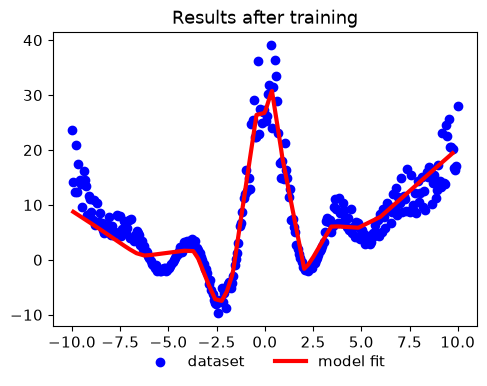

In [11]:
sz = [1, 32, 64, 128]
for lay_sz in sz:
    print(f'lay_sz = {lay_sz}')
    history = NNInterpolator(nlay=4, lay_sz=lay_sz).fit(dls, lr=0.1, nepochs=500, plot=True)

As we can see, the model with single-neuron layers results in a very poor fit consisting of a fusion of two straight lines. But as the amount of neurons per layer increases past a certain amount (e.g. 40-60), the fits become very similar. This shows that `lay_sz` is a pretty forgiving parameter that results in more subtle differences than `nlay`, which completely determines the model complexity.

## Learning rate (`lr`)

The learning rate is the most frequently tuned parameter in any neural network model, as it controls the proportion of the corrections applied to the coefficients during the training process (i.e. $w_{new} \sim w_{old} - lr \cdot \text{corr}(w_{old})$) and, therefore, interferes in how fast the model learns.

As it is tight to both the properties of the input dataset and the model architecture, it needs to be tweaked accordingly for each study case. E.g. `lr` tends to scale nearly linearly with `batch_sz`, so after modifying the amount of minibatches in your training set, you will probably need to also modify the learning rate accordingly.

For a fixed `batch_sz=64`, we will visualize the results obtained by training the model with different learning rates:

lr = 1


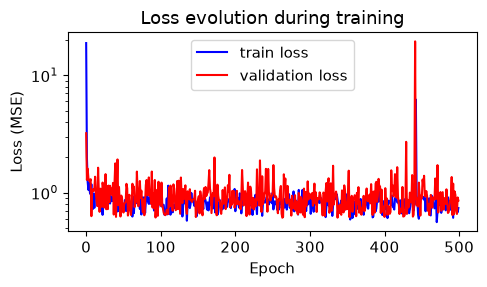

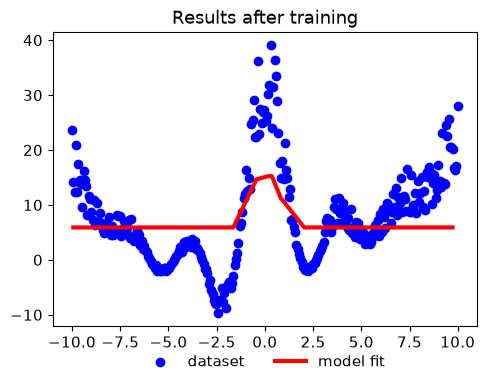

lr = 0.5


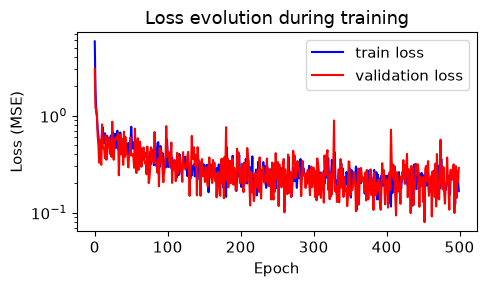

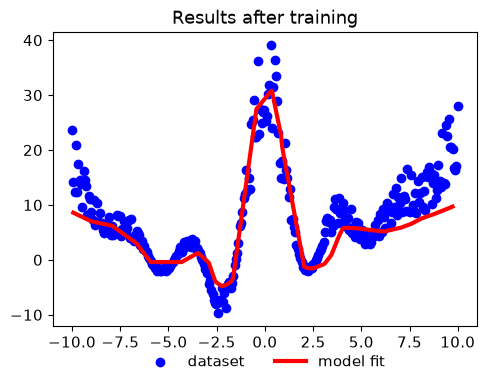

lr = 0.1


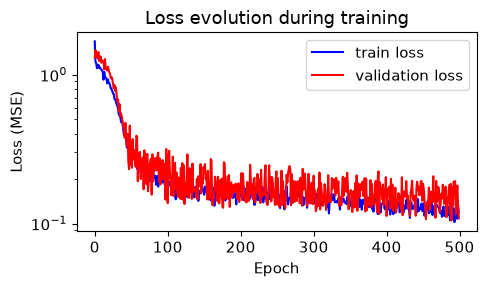

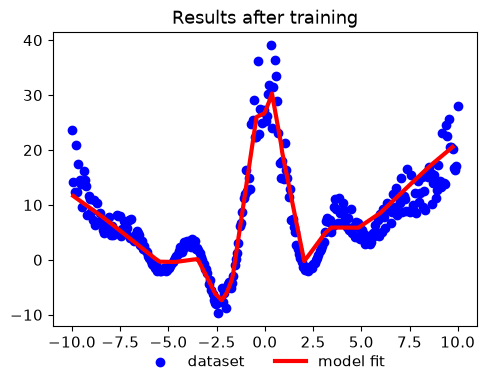

lr = 0.05


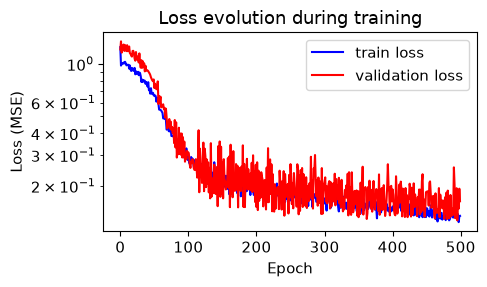

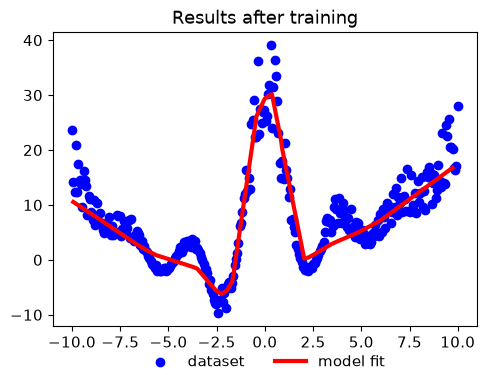

lr = 0.005


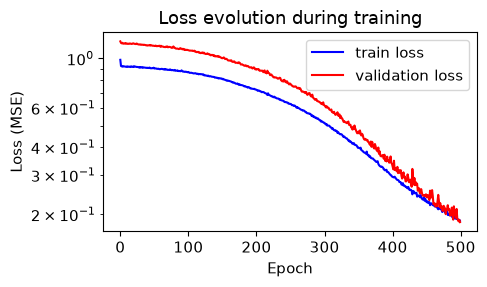

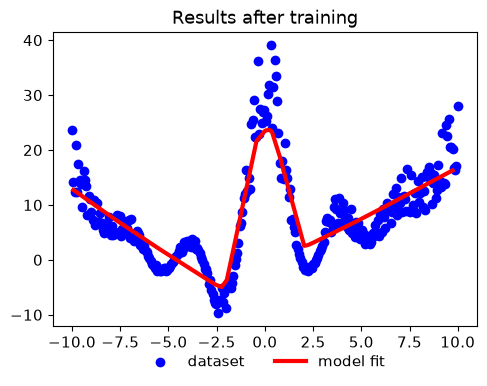

In [12]:
r = [1, 0.5, 0.1, 0.05, 0.005]

for lr in r:
    print(f'lr = {lr}')
    history = NNInterpolator(nlay=4, lay_sz=64).fit(dls, lr=lr, nepochs=500, plot=True)

As we can see, for a very big learning rate (`lr=1`) the model diverges and cannot properly fit the dataset. As it decreases, the resulting fit starts improving until it reaches values below `lr=1e-2`, where the fit gets worse and worse.

This happens because, on the one hand, very big learning rates tend to overcorrect the model coefficients and therefore make them jump between incorrect values. On the other hand, if the learning rate becomes too small, the coefficients are corrected in very short steps and thus the model ends up converging more slowly (i.e. it needs more epochs to reach the same results). The optimum value for `lr` is the one between these two cases, and in this particular example seems to be `lr=0.1`.

## Number of epochs

This is the simplest parameter to tune, as the more epochs a model is trained the more acurate it will fit to the dataset, but the longer the training will last. However, we will need to be careful of not overfitting our model, as we don't want outlier points to mess with our final function. In any case, as soon this overfitting starts to happen, the training loss function will have reached a constant value and the validation loss may start to increase, so we can simply stop before that happens.

nepochs = 1


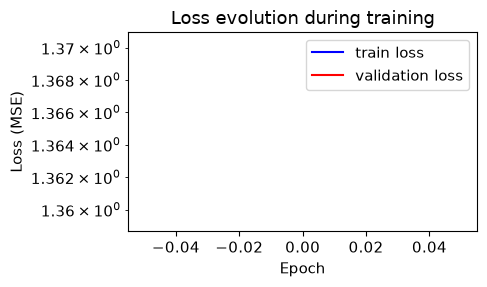

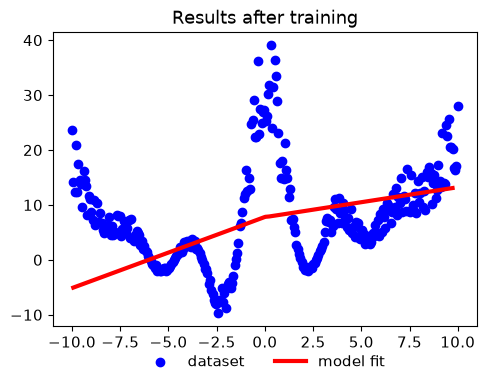

nepochs = 10


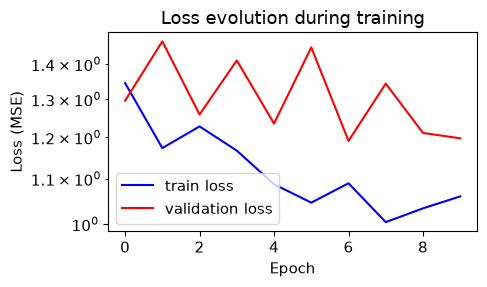

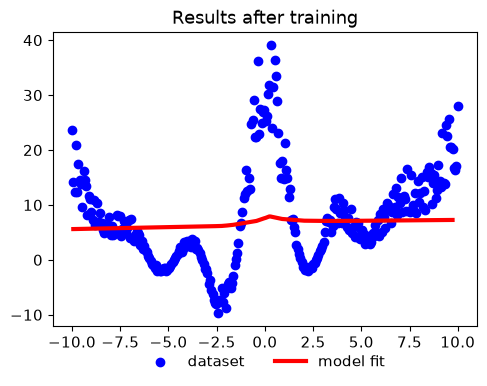

nepochs = 100


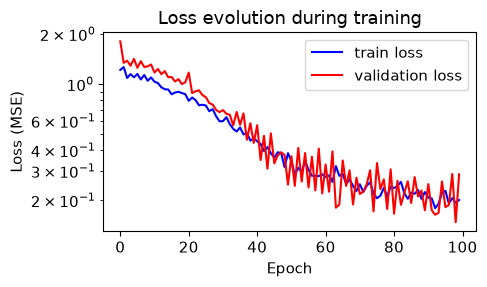

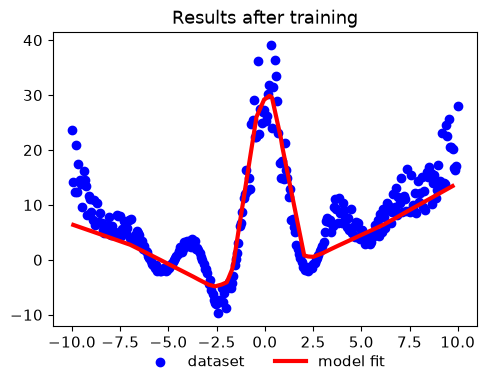

nepochs = 1000


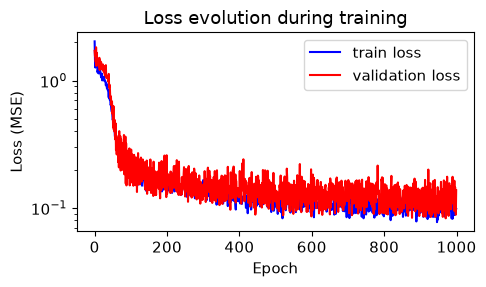

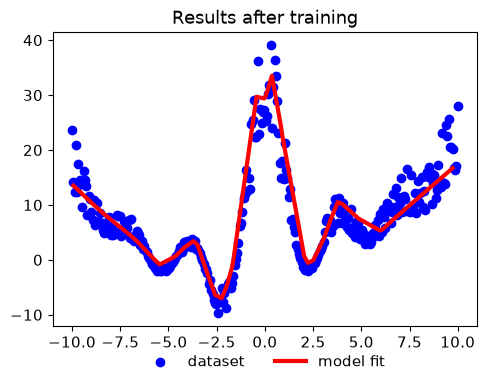

nepochs = 5000


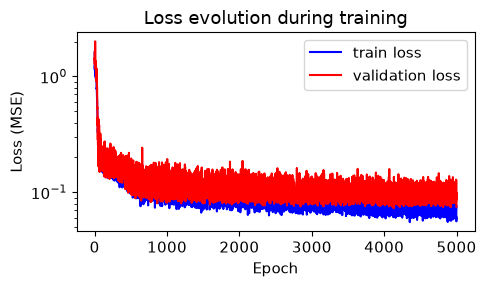

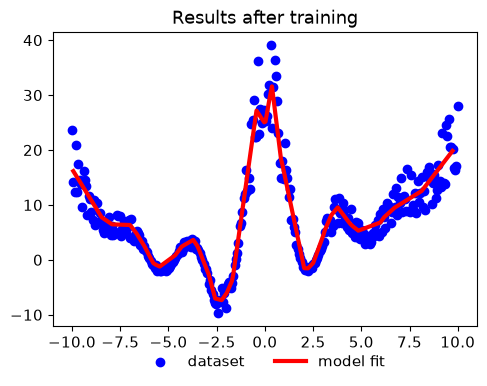

In [13]:
ep = [1, 10, 100, 1000, 5000]

for nepochs in ep:
    print(f'nepochs = {nepochs}')
    history = NNInterpolator(nlay=4, lay_sz=64).fit(dls, lr=0.1, nepochs=nepochs, plot=True)

As it can clearly be seen, as expected, the more epochs the better the fit, but the difference from `nepochs=1000` to `nepochs=5000` maybe doesn't justify the extra training time cost, as both losses become nearly contsant for `nepochs>1000`.

## Interpolation VS extrapolation

Now that we know how each of the parameters of the model affect the results after training, it is time to test the resulting model by inputing an array of x values and visualizing the corresponding array of outputs that it returns, which we would expect to match the real function behind the dataset.

In [19]:
model = NNInterpolator(nlay=4, lay_sz=64)
history = model.fit(dls, lr=0.1, nepochs=1000, plot=False)

The function used to create [example1a.csv](../examples/example1a.csv) was the following:

In [15]:
import torch

def real_func(x):
    return  2*torch.tanh(x) + 10*torch.sin(2*x)/x + x**4/1000 + torch.cosh(x/5)

Now we can define a vector of abscisses that covers the domain of our original dataset and bit more and call both the real function and the trained model:

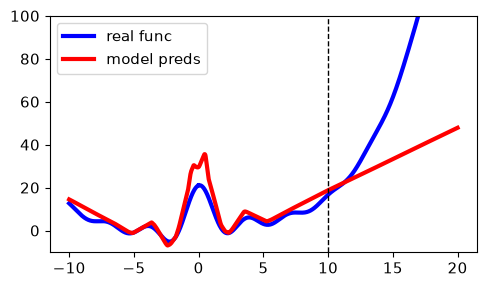

In [28]:
import matplotlib.pyplot as plt

x_test = torch.linspace(-10, 20, 1000)

preds = model.predict(x_test)
y_real = real_func(x_test)

fig, ax = plt.subplots(figsize=(5,3))
ax.plot(x_test, y_real, c='blue', lw=3, label='real func')
ax.plot(x_test, preds, c='red', lw=3, label='model preds')
ax.axvline(10, c='black', lw=1, ls='--')
ax.set_ylim(-10, 100)
plt.legend()
plt.tight_layout()
plt.show()

As we can see, to the left of the vertical dashed line (i.e. inside the domain of the original dataset) both curves seem pretty close together as expected. However, to the right (i.e. outside the original domain) the model fit follows a constant slope from the last point in the original domain and completely ignores the real function evolution.

This is not an error of our model but an intrinsic property of the way it has been trained. As during training it has only seen values from within the original domain, the model has modified its coefficients specifically to match the dataset shape in that region. So any further evolution of the real function outside this trained region will be unknown by the model.

Also, given that this particular neural network architecture (*a feed forward neural network, FFNN*) only processes the information in one direction (i.e. input --> output), it will be uncapable of inducing future patterns from the ones previously learnt.

**Interpolation** consists on filling the gaps within a known domain and **extrapolation**, on filling beyond that domain. This model is only able to perform the former.